# Data visualization with RUBELLA

First I load some example data already preprocessed with RABIES, the associated RABIES EPI template and seeds, then compute basic functional connectivity using seed-based analysis to capture the default mode network (DMN).

In [1]:
import glob
from rubella.data_obj import DataObject

CR_name = f'FD_cut30frames_bandpass0.01-0.2_cut30edges_mot6_aCompCor_smooth5'
rabies_out = f'/media/DATA3/gdesrosiersgregoire/preproc/117_Cryo_mediso_v/rabies_117_Cryo_mediso_v_20261027'
brain_mask_file = f'{rabies_out}/bold_datasink/commonspace_mask/commonspace_template_brain_mask_resampled.nii.gz'

timeseries_file_list = glob.glob(f'{rabies_out}/{CR_name}/confound_correction_datasink/cleaned_timeseries/*/*_cleaned.nii.gz')
timeseries_file_list.sort()
censoring_file_list = glob.glob(f'{rabies_out}/{CR_name}/confound_correction_datasink/frame_censoring_mask/*/*_frame_censoring_mask.csv')

data_obj = DataObject(brain_mask_file, timeseries_file_list, img_id_list=None, fname_split='_cleaned', censoring_file_list=censoring_file_list, verbose=True)


/media/DATA3/gdesrosiersgregoire/preproc/117_Cryo_mediso_v/rabies_117_Cryo_mediso_v_20261027/FD_cut30frames_bandpass0.01-0.2_cut30edges_mot6_aCompCor_smooth5/confound_correction_datasink/cleaned_timeseries/_split_name_sub-091_ses-1_task-rest_acq-EPI_bold/sub-091_ses-1_task-rest_acq-EPI_bold_cleaned.nii.gz
/media/DATA3/gdesrosiersgregoire/preproc/117_Cryo_mediso_v/rabies_117_Cryo_mediso_v_20261027/FD_cut30frames_bandpass0.01-0.2_cut30edges_mot6_aCompCor_smooth5/confound_correction_datasink/cleaned_timeseries/_split_name_sub-092_ses-1_task-rest_acq-EPI_bold/sub-092_ses-1_task-rest_acq-EPI_bold_cleaned.nii.gz
/media/DATA3/gdesrosiersgregoire/preproc/117_Cryo_mediso_v/rabies_117_Cryo_mediso_v_20261027/FD_cut30frames_bandpass0.01-0.2_cut30edges_mot6_aCompCor_smooth5/confound_correction_datasink/cleaned_timeseries/_split_name_sub-093_ses-1_task-rest_acq-EPI_bold/sub-093_ses-1_task-rest_acq-EPI_bold_cleaned.nii.gz
/media/DATA3/gdesrosiersgregoire/preproc/117_Cryo_mediso_v/rabies_117_Cryo_medi

In [2]:
'''
Fetch the RABIES template files
'''
from rubella.datasets import fetch_rabies_templates
EPICOMMON_files = fetch_rabies_templates('EPI')
template_file = EPICOMMON_files['template']

'''
Compute SBC on two seeds
'''
from rubella.basic_fc import seed_based_FC
SBC_dict={}
for seed_name in ['SS_frontal_seed','ACA_seed']:
    seed_file = EPICOMMON_files['seeds'][seed_name]
    SBC_dict[seed_name] = seed_based_FC(data_obj.timeseries_dict, data_obj.brain_mask_file, data_obj.img_id_list, seed_file, z_corr=False)


        size: (83, 127, 64) vs (65, 47, 64)
        spacing: (0.15000000596046448, 0.15000000596046448, 0.15000000596046448) vs (0.18888890743255615, 0.4000000059604645, 0.15000000596046448)

        The image is resampled onto the brain mask grid, with the assumption that
        both images are already aligned in physical space.
        
261102-17:43:56,965 nipype.utils WARNING:
	 A newer version (1.11.0) of nipy/nipype is available. You are using 1.10.0

        size: (83, 127, 64) vs (65, 47, 64)
        spacing: (0.15000000596046448, 0.15000000596046448, 0.15000000596046448) vs (0.18888890743255615, 0.4000000059604645, 0.15000000596046448)

        The image is resampled onto the brain mask grid, with the assumption that
        both images are already aligned in physical space.
        


## Visualization of single brain maps using `plot_brain`
`plot_brain` is the core plotting function implemented within RUBELLA. You can import it, then print and consult the full docstring for the function, to explore the various parameters options for that function.

In [3]:
from rubella.plotting import plot_brain
%matplotlib inline
help(plot_brain)

Help on function plot_brain in module rubella.plotting:

plot_brain(data, brain_mask, template_file=None, fig=None, ax=None, plot_size_scale=0.1, plane='coronal', slice_selection=6, crop_edges=[0, 0], slices_per_row=None, cmap='cold_hot', vmax=None, vmin=None, alpha=1, plot_cbar=False, fixed_threshold=None, percent_thresholding=False, top_percent=10, verbose=True)
    Plot a brain map as a series of slices along one of the three cardinal planes.
    
    The brain map can be overlaid on top of a template image in the same space.
    
    Parameters
    ----------
    data : numpy.ndarray
        The 1D array of shape (n_voxels,) representing the brain map. The array indices must
        have been previously generated using ``brain_mask``.
    
    brain_mask : str, pathlib.Path, SimpleITK.Image or nibabel.Nifti1Image
        The brain mask, either as the path to a Nifti file or a pre-loaded image.
    
    template_file : str or pathlib.Path, default=None
        Full path to the backg

/home/vscode/miniconda/envs/rabies_compute/lib/python3.9/site-packages/nilearn/datasets/__init__.py:87: FutureWarning: Fetchers from the nilearn.datasets module will be updated in version 0.9 to return python strings instead of bytes and Pandas dataframes instead of Numpy arrays.
  warn("Fetchers from the nilearn.datasets module will be "


Below I demonstrate step-by-step how you can customize your plot for a simple functional connectivity map of the default mode network in one subject. First, we can see what happens if we use the defaults, providing only the data vector outputted by seed-based connectivity, the brain mask, and background template. The function by default tries to automatically select 6 slices across the coronal plane.

Plotting along slices: [36, 30, 24, 18, 12, 6]
Generating a figure with dimensions (7.36666738986969, 0.9600000381469727)


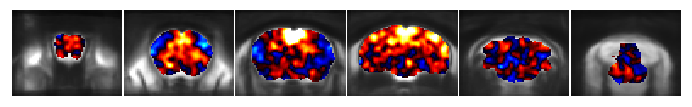

In [4]:
data=SBC_dict['ACA_seed'][data_obj.img_id_list[0]]
fig,ax,cbar = plot_brain(data,brain_mask_file,template_file)

### Customize slice selection and brain coverage

By using the defaults we can see part of the network, but the coverage is not ideal. Below is as an example for how one can revise and customize slice selection for ideal brain coverage.

First, we can decide instead to plot all slices using `slice_selection`, and plot a maximum of 10 slice per row using `slices_per_row`:

Plotting along slices: [38, 37, 36, 35, 34, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10, 9, 8, 7, 6, 5, 4]
Generating a figure with dimensions (12.27777898311615, 3.8400001525878906)


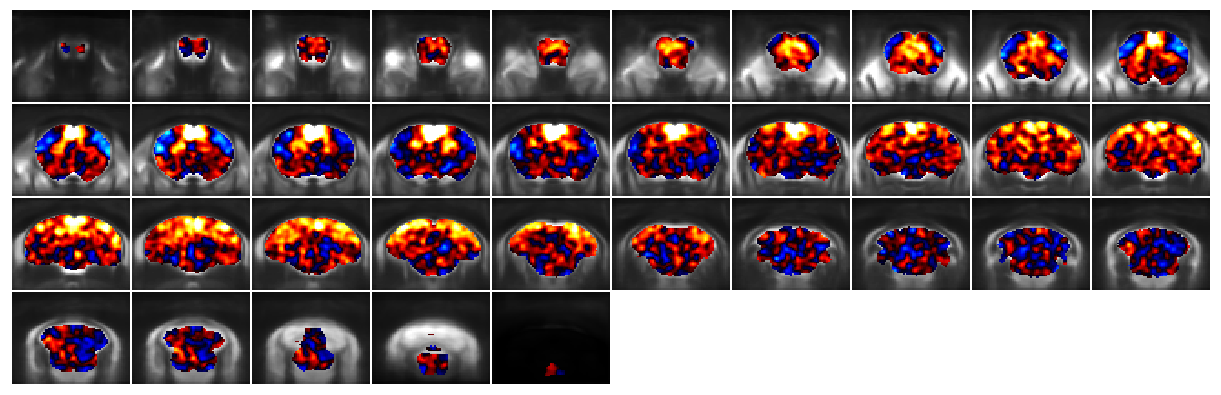

In [5]:
data=SBC_dict['ACA_seed'][data_obj.img_id_list[0]]

slice_selection='all'
slices_per_row=10
fig,ax,cbar = plot_brain(data,brain_mask_file,template_file,slice_selection=slice_selection,slices_per_row=slices_per_row)

Now we have the full picture, but this is too many slices. We can first take out the edge slices along the olfactory bulbs, cerebellow and brainstem regions that are of no interest. This is done conveniently using `crop_edges`, which takes out slices at the edges:

Plotting along slices: [32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 17, 16, 15, 14]
Generating a figure with dimensions (12.27777898311615, 1.9200000762939453)


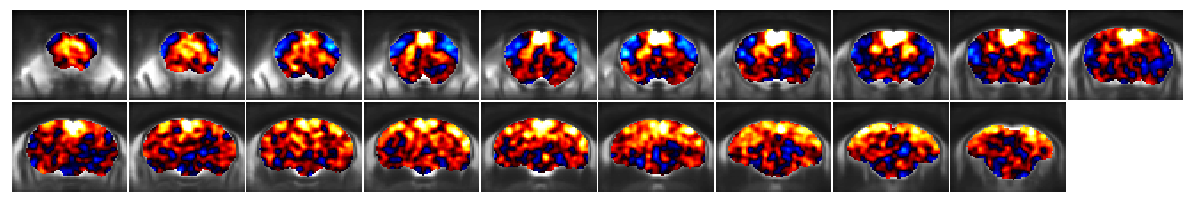

In [6]:
data=SBC_dict['ACA_seed'][data_obj.img_id_list[0]]

slice_selection='all'
slices_per_row=10
crop_edges=[14,14]
fig,ax,cbar = plot_brain(data,brain_mask_file,template_file,slice_selection=slice_selection,slices_per_row=slices_per_row,crop_edges=crop_edges)

We've got now a much cleaner view of the main brain regions. Perhaps this detailed visualization is useful in cases where you would want to see every slice across the network. But in most cases this is overkill, and we prefer to get a relatively concise brain coverage. Now that the `crop_edges` boundaries are set, the automated slice estimation will work better, we can now get a relatively concise but still detailed coverage with only 8 slices:

Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Generating a figure with dimensions (9.82222318649292, 0.9600000381469727)


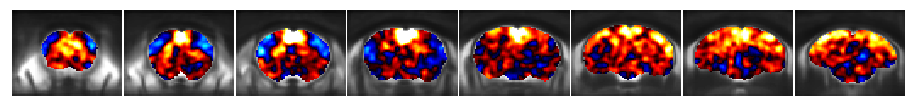

In [7]:
data=SBC_dict['ACA_seed'][data_obj.img_id_list[0]]

slice_selection=8
crop_edges=[14,14]

fig,ax,cbar = plot_brain(data,brain_mask_file,template_file,slice_selection=slice_selection,crop_edges=crop_edges)

It is also possible if desired to plot any custom set of slices, if `slice_selection` is instead a list of slice indices. Here is some random example:

Plotting along slices: [28, 26, 18, 10, 2]
Generating a figure with dimensions (6.138889491558075, 0.9600000381469727)


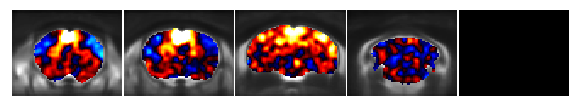

In [8]:
data=SBC_dict['ACA_seed'][data_obj.img_id_list[0]]

slice_selection=[28,26,18,10,2]

fig,ax,cbar = plot_brain(data,brain_mask_file,template_file,slice_selection=slice_selection)

Finally, the `crop_edges` parameter can further used to defining the bounding box of the image along any of the 3 cardinal axis. This is done by constructing a dictionary with a cropping value for each plane, as in the example below. Doing so here I can narrow the bounding box so that the image is further centered along the edges of the brain mask.

Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Generating a figure with dimensions (8.91555643081665, 0.7200000286102295)


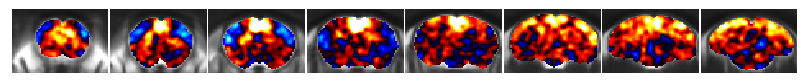

In [9]:
data=SBC_dict['ACA_seed'][data_obj.img_id_list[0]]

slice_selection=8
crop_edges={
    'coronal': [14,14],
    'horizontal': [8,8],
    'sagittal': [3,3]
}

fig,ax,cbar = plot_brain(data,brain_mask_file,template_file,slice_selection=slice_selection,crop_edges=crop_edges)

### Setting thresholds, colormap range and colorbar

The examples above are fully unthresholded and the colormap range is estimated from the input data. We can set a fixed range to the colormap by setting the maximal value with `vmax`, threshold any values below `fixed_threshold`, and add a colorbar:

Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Generating a figure with dimensions (9.82222318649292, 0.9600000381469727)


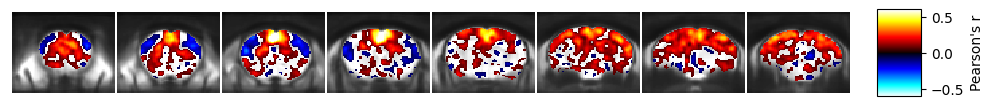

In [10]:
data=SBC_dict['ACA_seed'][data_obj.img_id_list[0]]

slice_selection=8
crop_edges=[14,14]

vmax=0.6
fixed_threshold=vmax*0.1
fig,ax,cbar = plot_brain(data,brain_mask_file,template_file,
                         slice_selection=slice_selection,crop_edges=crop_edges,
                         vmax=vmax,fixed_threshold=fixed_threshold,plot_cbar=True)
cbar.set_label("Pearson's r", fontsize=10)


An alternative thresholding technique is to keep a fixed percentage of the brain mask's anatomical coverage, only keeping the top voxels with the highest intensity (including strong negative values). This is activated with `percent_thresholding=True` and the percent of voxels displayed is set to 20 percent using `top_percent`. This is a sound strategy to display a consistent anatomical coverage for a given network, and provides a convenient delineation of the core DMN regions in this example:

Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Generating a figure with dimensions (9.82222318649292, 0.9600000381469727)


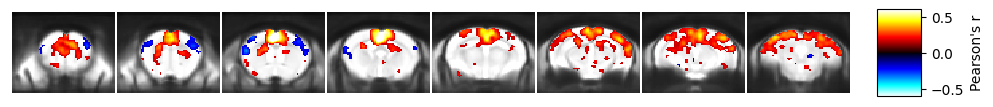

In [11]:
data=SBC_dict['ACA_seed'][data_obj.img_id_list[0]]

slice_selection=8
crop_edges=[14,14]

vmax=0.6
fig,ax,cbar = plot_brain(data,brain_mask_file,template_file,
                         slice_selection=slice_selection,crop_edges=crop_edges,
                         vmax=vmax,percent_thresholding=True,top_percent=20,plot_cbar=True)
cbar.set_label("Pearson's r", fontsize=10)


### Customizing plane of view, and assembling multiple plots into one figure

The plotting function is not limited to coronal views, but can plot along any of the 3 cardinal axes: 'coronal', 'horizontal' or 'sagittal'. Below are the example after I've tuned the `crop_edges` parameter for each axis individually.

Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Generating a figure with dimensions (9.82222318649292, 0.7800000309944153)
Plotting along slices: [46, 42, 39, 36, 32, 29, 26, 22]
Generating a figure with dimensions (9.82222318649292, 1.0800000160932541)
Plotting along slices: [47, 43, 39, 35, 31, 27, 23, 19]
Generating a figure with dimensions (8.640000128746033, 0.7800000309944153)


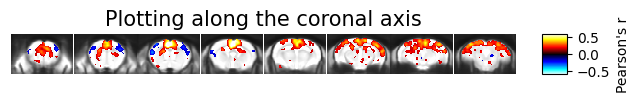

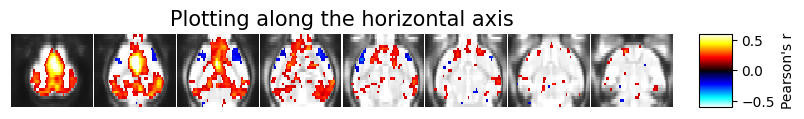

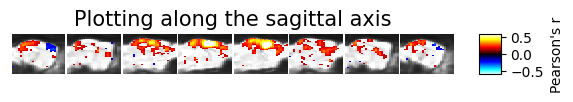

In [12]:
data=SBC_dict['ACA_seed'][data_obj.img_id_list[0]]

slice_selection=8
vmax=0.6

for plane,crop_edges in zip(
    ['coronal', 'horizontal', 'sagittal'],
    [
    {'coronal': [14,14], 'horizontal': [6,6]},
    {'horizontal': [4+12,15+6],'coronal':[10,10]},
    {'sagittal': [10+5,10+7],'coronal':[10,10], 'horizontal': [6,6]},
    ]
    ):
    fig,ax,cbar = plot_brain(data,brain_mask_file,template_file,
                            plane=plane, slice_selection=slice_selection,crop_edges=crop_edges,
                            vmax=vmax,percent_thresholding=True,top_percent=20,plot_cbar=True)
    ax.set_title(f"Plotting along the {plane} axis", fontsize=15)
    cbar.set_label("Pearson's r", fontsize=10)


It is also possible to pass a pre-generated matplotlib figure with subplots to each `plot_brain` call so that all planes are displayed in a single figure. This is done by filling the `fig` and `ax` input parameters, as in this example:

Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [46, 42, 39, 36, 32, 29, 26, 22]
Plotting along slices: [47, 43, 39, 35, 31, 27, 23, 19]


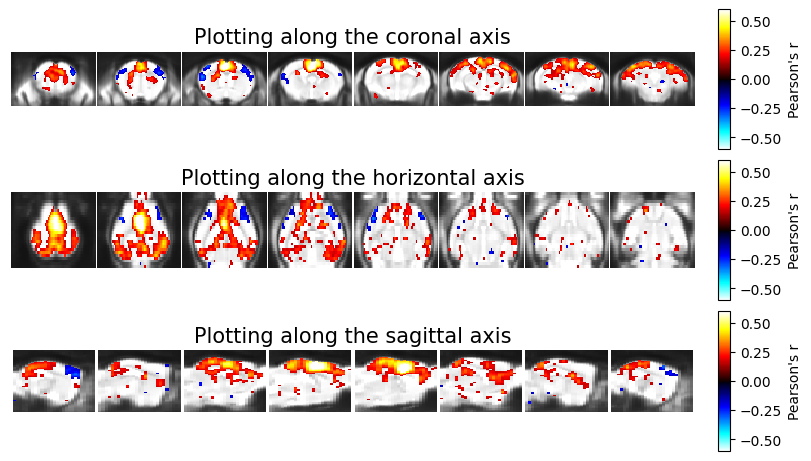

In [13]:
data=SBC_dict['ACA_seed'][data_obj.img_id_list[0]]
slice_selection=8
vmax=0.6

import matplotlib.pyplot as plt
fig,axes = plt.subplots(3,1, figsize=(slice_selection,3*1.5), constrained_layout=True)


for plane,crop_edges,ax in zip(
    ['coronal', 'horizontal', 'sagittal'],
    [
    {'coronal': [14,14], 'horizontal': [6,6]},
    {'horizontal': [4+12,15+6],'coronal':[10,10]},
    {'sagittal': [10+5,10+7],'coronal':[10,10], 'horizontal': [6,6]},
    ],
    axes,
    ):

    fig,ax,cbar = plot_brain(data,brain_mask_file,template_file,
                             fig=fig,ax=ax,
                            plane=plane, slice_selection=slice_selection,crop_edges=crop_edges,
                            vmax=vmax,percent_thresholding=True,top_percent=20,plot_cbar=True)
    ax.set_title(f"Plotting along the {plane} axis", fontsize=15)
    cbar.set_label("Pearson's r", fontsize=10)


### Automatically line a list of brain maps using `plot_many_brains`

The `plot_many_brains` function is a loop around the `plot_brain` function, and inherits most of its parameters. The main difference is that it takes a `data_list` input, which should be a list of vector arrays each of which describes a brain map. We can use this now to visualize the functional connectivity maps across all scans in the loaded dataset, by looping through the `img_id_list` of the `DataObject`. For this, its good to set a fixed `vmax` and thresholding values so that the colormap range is consistent across images. If needed, `plot_size_scale` is a scalar that controls the figure size, so if the figure is too big/small you can use this parameter.

With the example dataset below, we can now conveniently compare across individual subjects that mapping of the DMN network:

Plotting along slices: [37, 33, 29, 26, 22, 19, 15, 11]
Generating a figure with dimensions (9.82222318649292, 14.40000057220459), 15 rows and 1 columns.


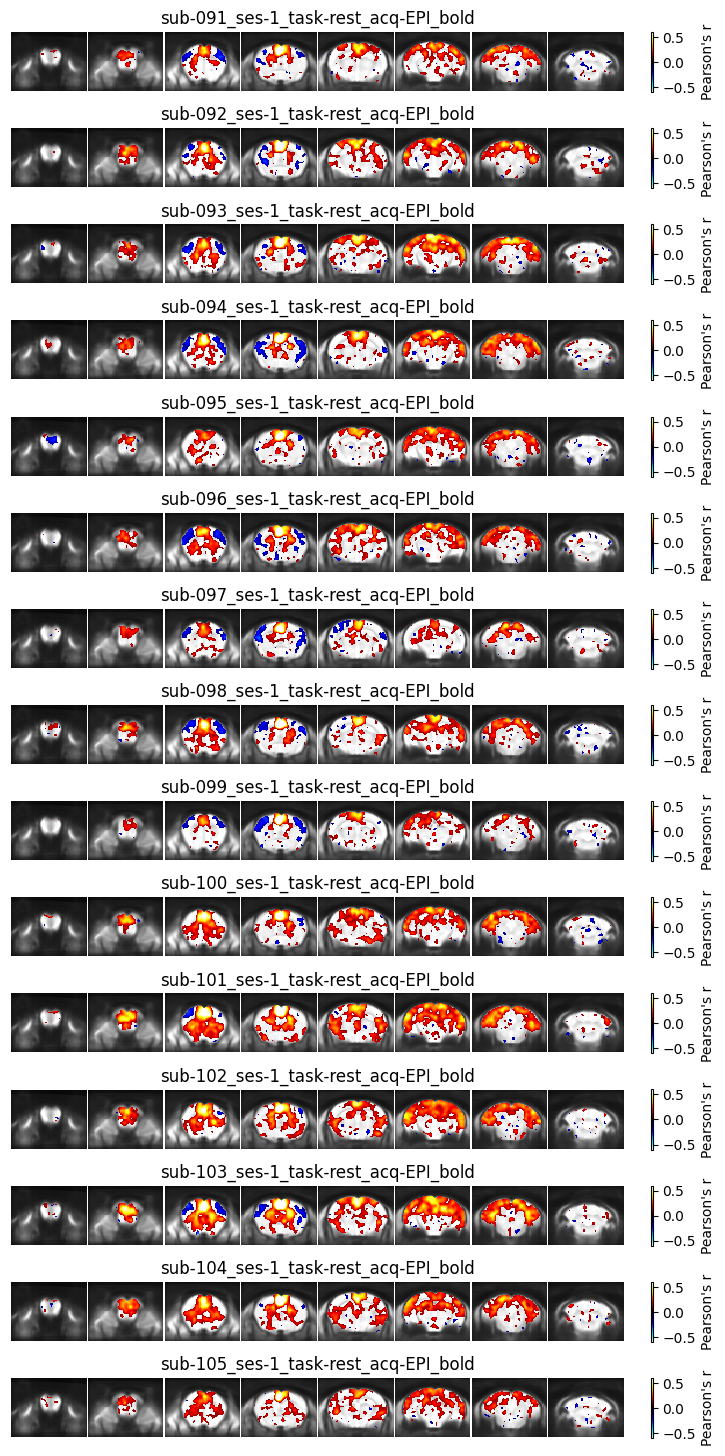

In [14]:
from rubella.plotting import plot_many_brains

data_list = [SBC_dict['ACA_seed'][img_id] for img_id in data_obj.img_id_list]
slice_selection=8
crop_edges=[6,10]

vmax=0.6
fixed_threshold=vmax*0.2

plot_size_scale=0.1
fig,ax_list,cbar_list = plot_many_brains(data_list,brain_mask_file,template_file,
                                         plot_size_scale=plot_size_scale,
                                         slice_selection=slice_selection,crop_edges=crop_edges,
                                         vmax=vmax,fixed_threshold=fixed_threshold,plot_cbar=True)

# here loop through the axis to write the associated img_id as title and add a colorbar label
for cbar,ax,img_id in zip(cbar_list,ax_list,data_obj.img_id_list):
    cbar.set_label("Pearson's r", fontsize=10)
    ax.set_title(img_id, fontsize=12)
